# 07 · POD en couleur + réseau

Même chaîne que le notebook 06, mais **en couleur** : on garde les trois canaux R, V, B au lieu de passer en noir et blanc.

**Pourquoi** : sur les pires erreurs du notebook 06, l'eau à l'ombre et les cailloux à l'ombre avaient la même intensité en noir et blanc. En couleur, l'eau reste bleu-vert et les cailloux gris : on espère que la POD sépare mieux les deux.

**Ce qui change par rapport au 06** :
- `normaliser_couleur` : pour **chaque canal** R, V, B, on enlève sa moyenne sur l'image et on divise par son écart type (comme `centrer` + `reduire` du notebook 05). Ça retire aussi les dominantes de couleur globales (aube bleue, lumière orangée du soir), mais garde les différences de couleur à l'intérieur de l'image.
- Chaque photo devient un vecteur de 150 × 459 × 3 = 206 550 valeurs (3 fois plus qu'en noir et blanc).

**Ce qui ne change pas** : même bande recalée (y ∈ [500, 1100], marge 40 px), même réduction à 1/4, même découpage train / test (script d'Aymen), POD sur les photos exploitables du train seulement, même réseau (64, 32), mêmes valeurs de K. Les résultats sont donc directement comparables au noir et blanc.

Les figures sont enregistrées dans `figures/couleur/`.

In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "donnees").is_dir())
IMAGES = ROOT / "data" / "images"
FIG = ROOT / "etudes" / "pod" / "figures" / "couleur"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 70

W0 = 1919
Y0, Y1 = 500, 1100           # bande autour de la frontière (comme le notebook 06)
MARGE = 40                   # marge gauche / droite pour le recalage horizontal
ECHELLE = 4                  # bandes réduites à 1/4 pour la POD
TAILLE = ((W0 - 2 * MARGE) // ECHELLE, (Y1 - Y0) // ECHELLE)   # (largeur, hauteur) = (459, 150)
h, w = TAILLE[1], TAILLE[0]

cat = pd.read_csv(ROOT / "donnees" / "catalogue_images.csv").set_index("fichier")
split = pd.read_csv(ROOT / "donnees" / "split_train_test.csv").set_index("fichier")["split"]
annot = pd.concat([pd.read_csv(f) for f in sorted((ROOT / "donnees" / "annotations").glob("niveau_*.csv"))])
annot = annot.dropna(subset=["niveau_px"]).drop_duplicates("fichier").set_index("fichier")
hauteur = annot["niveau_px"] - cat["decalage_y"].reindex(annot.index)    # hauteur d'eau corrigée du mouvement de la caméra

## 1. Les deux fonctions

In [2]:
def decouper(img, decalage_x=0.0, decalage_y=0.0):
    """Bande y ∈ [Y0, Y1], x ∈ [MARGE, W0 - MARGE] (pleine résolution), décalée du mouvement de la caméra. Taille fixe."""
    s = img.size[0] / W0
    gauche, haut = round((MARGE + decalage_x) * s), round((Y0 + decalage_y) * s)
    return img.crop((gauche, haut, gauche + round((W0 - 2 * MARGE) * s), haut + round((Y1 - Y0) * s)))


def normaliser_couleur(img):
    """Pour chaque canal R, V, B : (canal - sa moyenne) / son écart type. Renvoie un tableau float32 (H, W, 3)."""
    x = np.asarray(img.convert("RGB"), dtype=np.float64)
    moyenne = x.mean(axis=(0, 1))
    ecart_type = x.std(axis=(0, 1))
    return ((x - moyenne) / np.where(ecart_type > 0, ecart_type, 1.0)).astype(np.float32)


def charger(nom):
    """decouper (recalée) puis normaliser_couleur, sur la photo décodée à 1/ECHELLE. Renvoie un vecteur float32."""
    img = Image.open(IMAGES / nom)
    img.draft("RGB", (img.size[0] // ECHELLE, img.size[1] // ECHELLE))
    bande = decouper(img.convert("RGB"), cat.at[nom, "decalage_x"], cat.at[nom, "decalage_y"]).resize(TAILLE)
    return normaliser_couleur(bande).ravel()


def afficher(x):
    """Vecteur couleur normalisé -> image RGB affichable (moyenne ± 3 écarts types ramenés sur [0, 1])."""
    return np.clip(np.asarray(x).reshape(h, w, 3) / 6 + 0.5, 0, 1)

Vérification sur quelques photos : bande en couleur, puis bande normalisée canal par canal.

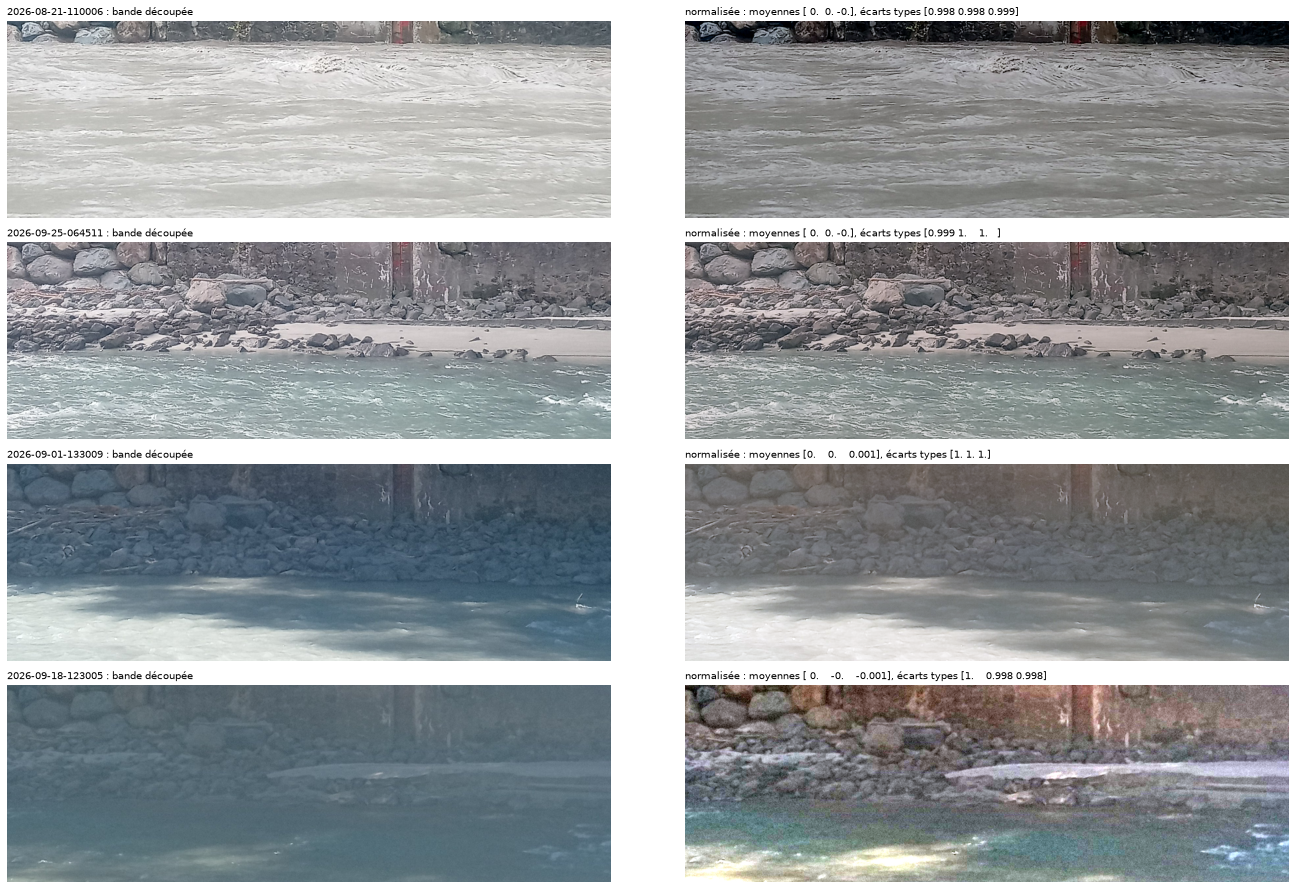

In [3]:
exemples = annot.sort_values("niveau_px").index[np.linspace(0, len(annot) - 1, 4).astype(int)]
fig, axes = plt.subplots(len(exemples), 2, figsize=(20, 3.2 * len(exemples)))
for ligne, nom in zip(axes, exemples):
    img = Image.open(IMAGES / nom)
    bande = decouper(img, cat.at[nom, "decalage_x"], cat.at[nom, "decalage_y"])
    x = normaliser_couleur(bande)
    ligne[0].imshow(bande); ligne[0].set_title(f"{nom[:-4]} : bande découpée", loc="left", fontsize=10)
    ligne[1].imshow(np.clip(x / 6 + 0.5, 0, 1))
    ligne[1].set_title(f"normalisée : moyennes {x.mean(axis=(0, 1)).round(3)}, écarts types {x.std(axis=(0, 1)).round(3)}", loc="left", fontsize=10)
    for ax in ligne:
        ax.axis("off")
plt.tight_layout()

## 2. POD en couleur

Photos exploitables du train pour construire la base, photos test seulement projetées dessus. Méthode des snapshots : matrice de corrélation entre photos (n × n), puis
- coefficients des photos train : $a = U\Sigma$ (directement à partir des vecteurs propres),
- coefficients des photos test : $(X_{test} - \bar{x})\,(X - \bar{x})^T\,U\,\Sigma^{-1}$, sans avoir à stocker tous les modes (3 493 modes × 206 550 valeurs = 2,9 Go).

In [4]:
utiles = cat.index[(cat["exploitable"] == "oui") & cat["decalage_y"].notna()]
fichiers = {s: sorted(f for f in utiles if split.get(f) == s) for s in ("train", "test")}
t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    X = {s: np.stack(list(ex.map(charger, f))) for s, f in fichiers.items()}
print({s: x.shape for s, x in X.items()}, f"-> bandes de {h} x {w} x 3 | chargement {time.time() - t0:.0f} s")

t0 = time.time()
xbar = X["train"].mean(axis=0)
A = X["train"] - xbar
valeurs, vecteurs = np.linalg.eigh((A @ A.T).astype(np.float64))
ordre = np.argsort(valeurs)[::-1]
valeurs, vecteurs = np.clip(valeurs[ordre], 0, None), vecteurs[:, ordre]
K_MAX = len(A) - 1                                 # le dernier mode est nul (on a retiré la moyenne)
valeurs, vecteurs = valeurs[:K_MAX], vecteurs[:, :K_MAX]
sigma = np.sqrt(valeurs)
energie = valeurs / valeurs.sum()

coefs = {"train": vecteurs * sigma}                                                      # U Σ
G = (X["test"] - xbar) @ A.T                                                             # (n_test, n_train)
coefs["test"] = (G.astype(np.float64) @ vecteurs) / sigma
print(f"POD : {time.time() - t0:.0f} s")
for k in (1, 5, 10, 20, 50, 100, 200, 300, 500, 1000, 2000, K_MAX):
    print(f"{k:5d} modes : {100 * energie[:k].sum():5.1f} % de l'énergie")


def mode(k):
    """Mode k (à partir de 1), vecteur de taille h * w * 3."""
    return (A.T @ vecteurs[:, k - 1].astype(np.float32)) / np.float32(sigma[k - 1])


def reconstruire(a, K):
    """xbar + somme des K premiers modes pondérés par les coefficients a (sans stocker les modes)."""
    poids = vecteurs[:, :K] @ (a[:K] / sigma[:K])
    return xbar + A.T @ poids.astype(np.float32)

{'train': (3494, 206550), 'test': (883, 206550)} -> bandes de 150 x 459 x 3 | chargement 8 s


POD : 10 s
    1 modes :  23.1 % de l'énergie
    5 modes :  50.4 % de l'énergie
   10 modes :  61.3 % de l'énergie
   20 modes :  69.7 % de l'énergie
   50 modes :  77.5 % de l'énergie
  100 modes :  81.6 % de l'énergie
  200 modes :  85.0 % de l'énergie
  300 modes :  86.8 % de l'énergie
  500 modes :  89.3 % de l'énergie
 1000 modes :  93.2 % de l'énergie
 2000 modes :  97.5 % de l'énergie
 3493 modes : 100.0 % de l'énergie


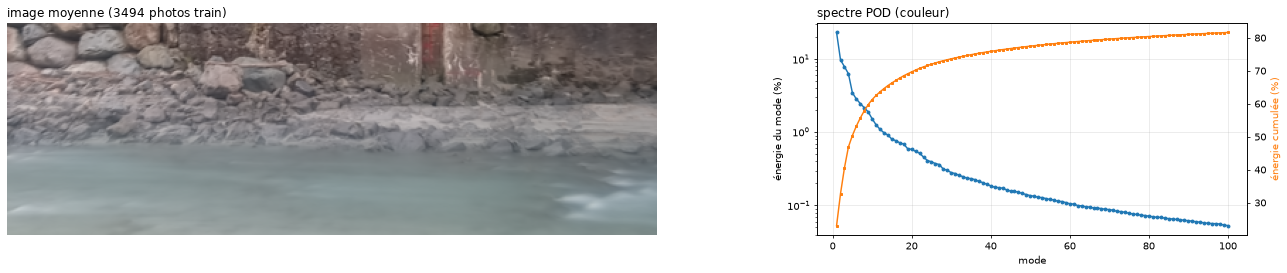

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(20, 4), gridspec_kw={"width_ratios": [2, 1]})
ax[0].imshow(afficher(xbar)); ax[0].set_title(f"image moyenne ({len(A)} photos train)", loc="left"); ax[0].axis("off")
K = np.arange(1, 101)
ax[1].semilogy(K, 100 * energie[:100], "o-", ms=3)
ax2 = ax[1].twinx(); ax2.plot(K, 100 * np.cumsum(energie[:100]), "s-", ms=3, color="tab:orange")
ax[1].set_xlabel("mode"); ax[1].set_ylabel("énergie du mode (%)"); ax2.set_ylabel("énergie cumulée (%)", color="tab:orange")
ax[1].grid(alpha=.3); ax[1].set_title("spectre POD (couleur)", loc="left")
plt.tight_layout()

### Les modes

Un mode couleur est affiché comme une image : gris = 0, chaque canal plus clair / plus sombre que la moyenne selon le signe. Figures complètes enregistrées : `figures/couleur/modes_01_a_50.png` et `modes_100_200_400.png`.

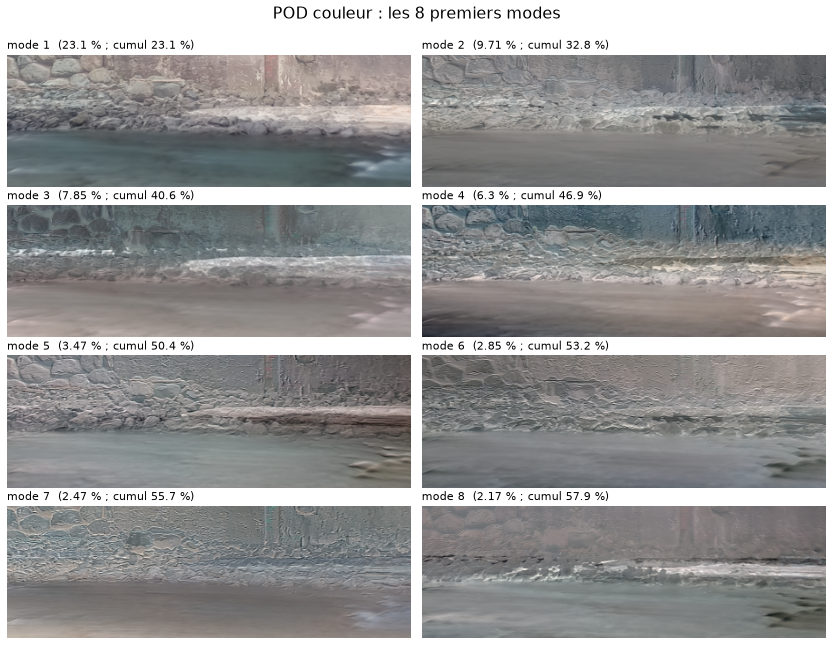

In [6]:
def image_mode(m):
    m = m.reshape(h, w, 3)
    return np.clip(0.5 + m / (2 * np.abs(m).max()), 0, 1)


def planche_modes(liste, ncol, chemin, titre):
    nl = int(np.ceil(len(liste) / ncol))
    fig, axes = plt.subplots(nl, ncol, figsize=(6 * ncol, 2.3 * nl))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, k in zip(np.atleast_1d(axes).ravel(), liste):
        ax.imshow(image_mode(mode(k)))
        ax.set_title(f"mode {k}  ({100 * energie[k - 1]:.3g} % ; cumul {100 * energie[:k].sum():.1f} %)", loc="left", fontsize=11)
    fig.suptitle(titre, fontsize=16, y=1.0)
    plt.tight_layout()
    fig.savefig(chemin, dpi=110, bbox_inches="tight")
    return fig


planche_modes(list(range(1, 51)), 5, FIG / "modes_01_a_50.png",
              f"POD couleur des bandes prétraitées : modes 1 à 50  —  {len(A)} photos train")
plt.close()
fig = planche_modes([100 * 2 ** i for i in range(10) if 100 * 2 ** i <= K_MAX], 2, FIG / "modes_100_200_400.png",
                    "POD couleur : modes 100, 200, 400, ...")
plt.close()
fig = planche_modes(list(range(1, 9)), 2, FIG / "modes_01_a_08.png", "POD couleur : les 8 premiers modes")
plt.show()

### Les coefficients en fonction de la hauteur d'eau (photos train annotées)

3493 photos train annotées


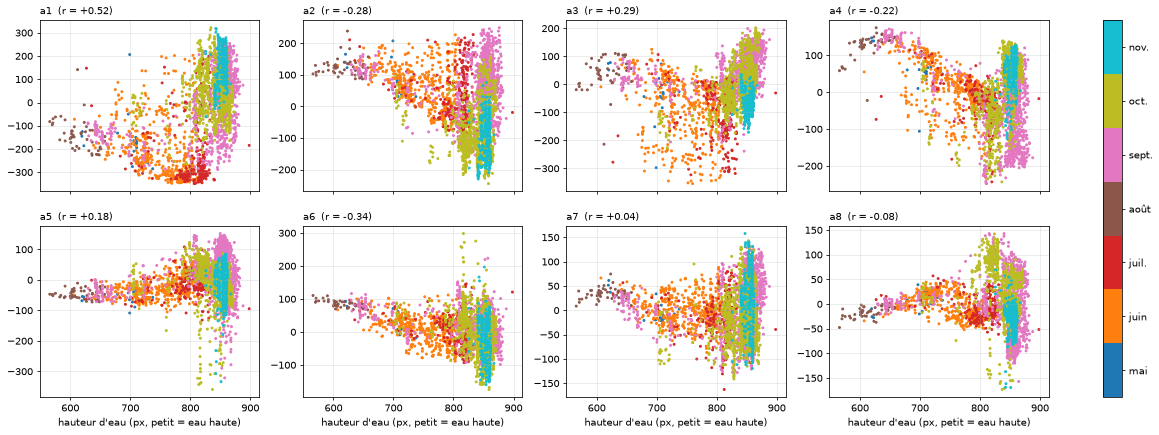

In [7]:
dates = pd.to_datetime(pd.Series(fichiers["train"]).str[:17], format="%Y-%m-%d-%H%M%S")
h_eau = hauteur.reindex(fichiers["train"]).to_numpy()
ok = np.isfinite(h_eau)
MOIS = {5: "mai", 6: "juin", 7: "juil.", 8: "août", 9: "sept.", 10: "oct.", 11: "nov."}
cmap_mois = plt.get_cmap("tab10", len(MOIS))
fig, axes = plt.subplots(2, 4, figsize=(20, 7), sharex=True)
for k, ax in enumerate(axes.ravel()):
    a = coefs["train"][ok, k]
    sc = ax.scatter(h_eau[ok], a, s=4, c=dates[ok].dt.month, cmap=cmap_mois, vmin=4.5, vmax=11.5)
    ax.set_title(f"a{k + 1}  (r = {np.corrcoef(h_eau[ok], a)[0, 1]:+.2f})", loc="left", fontsize=10); ax.grid(alpha=.3)
for ax in axes[1]:
    ax.set_xlabel("hauteur d'eau (px, petit = eau haute)")
cb = plt.colorbar(sc, ax=axes, fraction=0.02, ticks=list(MOIS)); cb.ax.set_yticklabels(MOIS.values())
print(ok.sum(), "photos train annotées")
plt.show()

## 3. Réseau sur les K premiers coefficients

Exactement le même protocole que le notebook 06 : entrée = K premiers coefficients (centrés réduits sur le train), sortie = hauteur d'eau, MLP (64, 32) avec arrêt anticipé, 3 graines ; référence = régression ridge.

In [8]:
jeux = {}
for s in ("train", "test"):
    y = hauteur.reindex(fichiers[s]).to_numpy()
    g = np.isfinite(y)
    jeux[s] = (coefs[s][g], y[g], np.array(fichiers[s])[g])
ytr, yte, noms_te = jeux["train"][1], jeux["test"][1], jeux["test"][2]
print({s: len(j[1]) for s, j in jeux.items()}, "photos annotées")


def entrainer(Ctr, Cte, K, graines=(0, 1, 2)):
    """Renvoie (prédictions test de chaque graine, prédictions train de chaque graine, prédiction ridge, itérations)."""
    sx = StandardScaler().fit(Ctr[:, :K])
    Xtr, Xte = sx.transform(Ctr[:, :K]), sx.transform(Cte[:, :K])
    my, sy = ytr.mean(), ytr.std()
    p_lin = Ridge(alpha=1.0).fit(Xtr, (ytr - my) / sy).predict(Xte) * sy + my
    p_te, p_tr, it = [], [], []
    for g in graines:
        mlp = MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, learning_rate_init=1e-3, max_iter=3000,
                           early_stopping=True, validation_fraction=0.1, n_iter_no_change=50, random_state=g)
        mlp.fit(Xtr, (ytr - my) / sy)
        p_te.append(mlp.predict(Xte) * sy + my); p_tr.append(mlp.predict(Xtr) * sy + my); it.append(mlp.n_iter_)
    return p_te, p_tr, p_lin, np.mean(it)


KS = [1, 2, 3, 5, 10, 20, 50, 100, 200, 300, 500, 750, 1000, 1500, 2000, 3000, K_MAX]
resultats, predictions, predictions_lin, iterations = [], {}, {}, {}
t0 = time.time()
for K in KS:
    p_te, p_tr, p_lin, it = entrainer(jeux["train"][0], jeux["test"][0], K)
    predictions[K], predictions_lin[K], iterations[K] = np.mean(p_te, axis=0), p_lin, it
    resultats.append({"K": K, "réseau : erreur train (px)": np.mean([np.abs(p - ytr).mean() for p in p_tr]),
                      "réseau : erreur test (px)": np.mean([np.abs(p - yte).mean() for p in p_te]),
                      "écart entre graines (px)": np.std([np.abs(p - yte).mean() for p in p_te]),
                      "réseau : test à 10 px près (%)": 100 * np.mean([np.mean(np.abs(p - yte) <= 10) for p in p_te]),
                      "linéaire : erreur test (px)": np.abs(p_lin - yte).mean()})
resultats = pd.DataFrame(resultats).set_index("K").round(1)
print(f"entraînements : {time.time() - t0:.0f} s")
resultats

{'train': 3493, 'test': 883} photos annotées


entraînements : 419 s


,réseau : erreur train (px),réseau : erreur test (px),écart entre graines (px),réseau : test à 10 px près (%),linéaire : erreur test (px)
K,,,,,
1,29.7,54.5,0.7,9.1,47.2
2,20.0,27.9,0.3,25.0,42.4
3,13.2,29.5,1.0,26.8,38.6
5,8.5,25.3,0.6,25.4,31.9
10,5.2,18.9,0.6,31.8,21.1
20,4.0,15.2,1.0,40.1,20.5
50,3.1,14.5,0.5,42.3,17.2
100,2.4,15.2,1.1,41.3,14.9
200,1.9,15.7,2.4,40.1,15.3


### Comparaison avec le noir et blanc (notebook 06)

On relit les coefficients POD noir et blanc enregistrés par le notebook 06 (`data/pod_bande.npz`) et on entraîne exactement le même réseau, pour tracer les deux courbes ensemble.

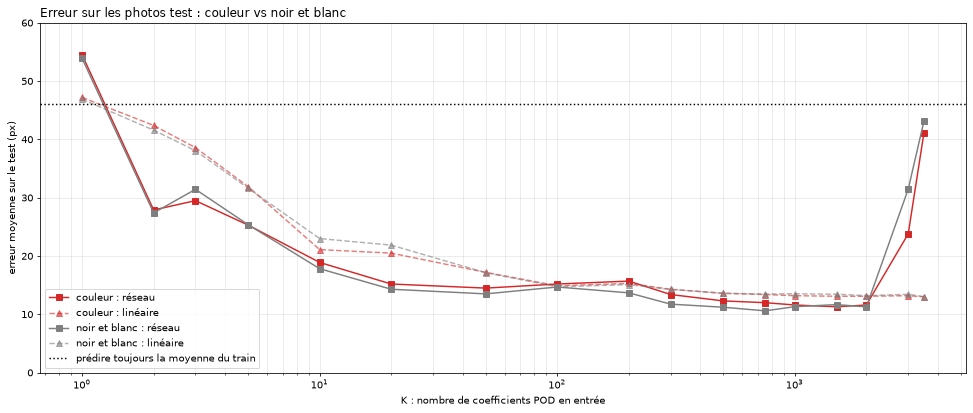

In [9]:
gris = np.load(ROOT / "data" / "pod_bande.npz")
def jeu_gris(s):
    f = gris[f"fichiers_{s}"]; y = hauteur.reindex(f).to_numpy(); g = np.isfinite(y)
    return gris[f"coefs_{s}"][g], y[g], f[g]
Gtr, gytr, _ = jeu_gris("train"); Gte, gyte, gnoms = jeu_gris("test")
assert np.array_equal(gnoms, noms_te) and np.allclose(gyte, yte), "mêmes photos test que le notebook 06"
resultats_gris, predictions_gris = {}, {}
for K in KS:
    if K > Gtr.shape[1]:
        continue
    p_te, _, p_lin, _ = entrainer(Gtr, Gte, K)
    predictions_gris[K] = np.mean(p_te, axis=0)
    resultats_gris[K] = {"réseau": np.mean([np.abs(p - yte).mean() for p in p_te]), "linéaire": np.abs(p_lin - yte).mean()}
resultats_gris = pd.DataFrame(resultats_gris).T

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(resultats.index, resultats["réseau : erreur test (px)"], "s-", color="tab:red", label="couleur : réseau")
ax.plot(resultats.index, resultats["linéaire : erreur test (px)"], "^--", color="tab:red", alpha=.6, label="couleur : linéaire")
ax.plot(resultats_gris.index, resultats_gris["réseau"], "s-", color="tab:gray", label="noir et blanc : réseau")
ax.plot(resultats_gris.index, resultats_gris["linéaire"], "^--", color="tab:gray", alpha=.6, label="noir et blanc : linéaire")
ax.axhline(np.abs(yte - ytr.mean()).mean(), color="k", ls=":", label="prédire toujours la moyenne du train")
ax.set_xscale("log"); ax.set_xlabel("K : nombre de coefficients POD en entrée"); ax.set_ylabel("erreur moyenne sur le test (px)")
ax.set_ylim(0, 60); ax.grid(alpha=.3, which="both"); ax.legend()
ax.set_title("Erreur sur les photos test : couleur vs noir et blanc", loc="left")
plt.tight_layout(); fig.savefig(FIG / "erreur_selon_K_couleur_vs_gris.png", dpi=110)

### Distribution des erreurs sur les photos test (couleur)

|erreur| (px) que 50 / 75 / 90 % des photos test ne dépassent pas :


réseau              linéaire            
       50 %  75 %   90 %     50 %  75 %  90 %
K                                            
1      47.2  86.9  101.2     47.6  64.7  83.4
2      21.0  35.9   57.4     40.0  54.4  78.5
3      22.3  39.7   59.7     33.2  51.9  81.2
5      20.7  35.2   47.0     26.6  40.5  66.1
10     14.5  24.9   37.7     16.9  30.6  43.1
20     12.6  19.9   28.1     19.5  28.4  38.4
50     11.0  18.9   26.7     13.6  26.4  35.2
100    10.8  18.7   26.4     13.6  21.1  29.7
200    11.5  18.8   26.8     14.3  21.9  29.3
300    11.0  18.0   24.9     13.2  20.5  28.2
500    10.1  16.2   23.1     12.3  19.1  25.7
750     9.9  16.0   22.2     12.1  18.3  25.7
1000    9.9  15.2   21.8     12.1  18.1  24.8
1500    9.3  14.6   21.6     12.0  18.0  24.8
2000   10.2  15.5   20.9     11.7  17.9  24.3
3000   21.0  30.6   39.5     11.6  18.5  25.0
3493   36.8  46.8   78.8     11.4  18.6  25.3

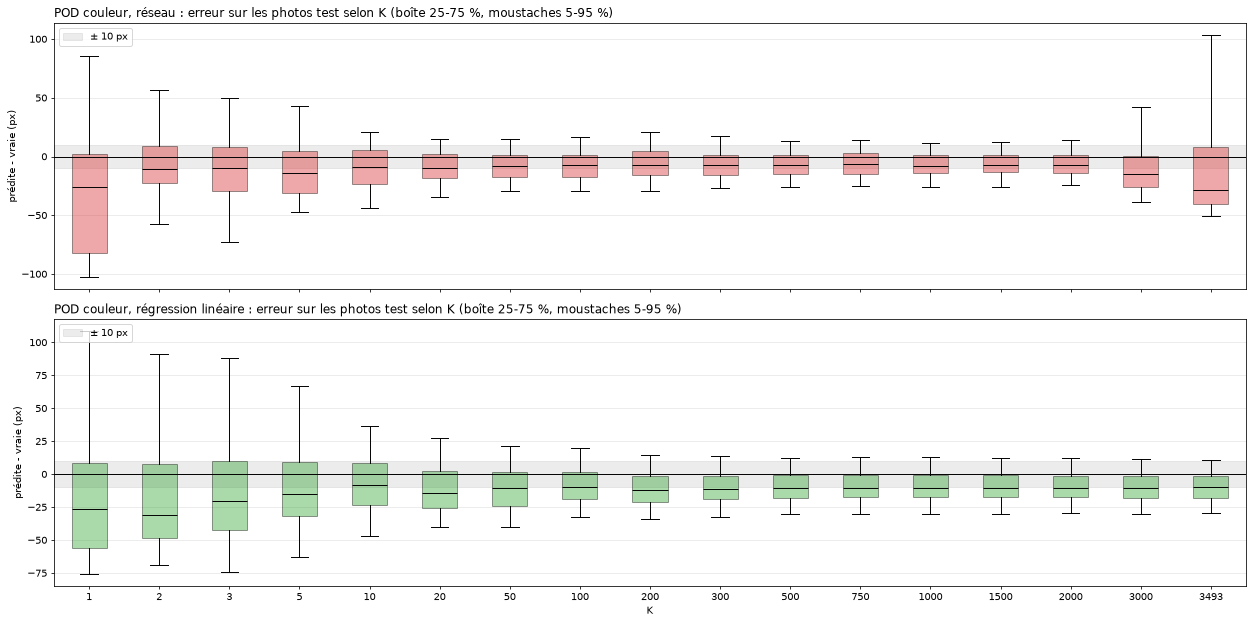

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(18, 9), sharex=True)
for ax, (nom, preds, couleur) in zip(axes, [("réseau", predictions, "tab:red"), ("régression linéaire", predictions_lin, "tab:green")]):
    ax.boxplot([preds[K] - yte for K in KS], whis=(5, 95), showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=couleur, alpha=.4), medianprops=dict(color="k"))
    ax.axhline(0, color="k", lw=1); ax.axhspan(-10, 10, color="gray", alpha=.15, label="± 10 px")
    ax.set_ylabel("prédite - vraie (px)"); ax.grid(alpha=.3, axis="y"); ax.legend(loc="upper left")
    ax.set_title(f"POD couleur, {nom} : erreur sur les photos test selon K (boîte 25-75 %, moustaches 5-95 %)", loc="left")
axes[1].set_xticks(range(1, len(KS) + 1), KS); axes[1].set_xlabel("K")
plt.tight_layout(); fig.savefig(FIG / "distribution_erreurs_selon_K.png", dpi=100)

q = pd.DataFrame({(nom, f"{int(100 * p)} %"): [np.quantile(np.abs(preds[K] - yte), p) for K in KS]
                  for nom, preds in [("réseau", predictions), ("linéaire", predictions_lin)] for p in (0.5, 0.75, 0.9)},
                 index=pd.Index(KS, name="K")).round(1)
print("|erreur| (px) que 50 / 75 / 90 % des photos test ne dépassent pas :")
q

### Le meilleur K

Comme dans le notebook 06, K est choisi sur l'erreur test : le chiffre est donc légèrement optimiste (même biais des deux côtés, la comparaison reste juste).

couleur : K = 1500, erreur moyenne 11.0 px | noir et blanc : K = 750, 10.3 px


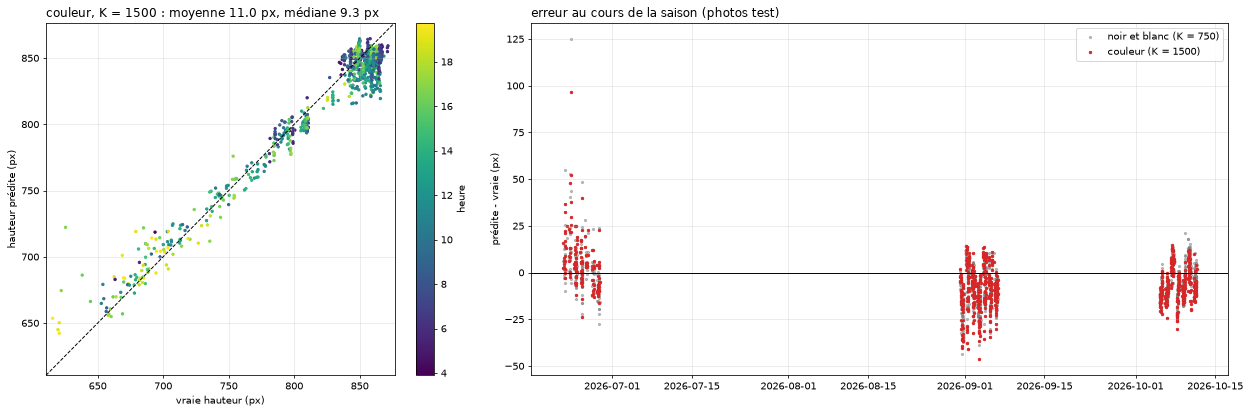

In [11]:
K_best = int(resultats["réseau : erreur test (px)"].idxmin())
K_gris = int(resultats_gris["réseau"].idxmin())
pred = predictions[K_best]; err = pred - yte
pred_g = predictions_gris[K_gris]; err_g = pred_g - yte
dates_te = pd.to_datetime(pd.Series(noms_te).str[:17], format="%Y-%m-%d-%H%M%S")
heures_te = (dates_te.dt.hour + dates_te.dt.minute / 60).to_numpy()
print(f"couleur : K = {K_best}, erreur moyenne {np.abs(err).mean():.1f} px | noir et blanc : K = {K_gris}, {np.abs(err_g).mean():.1f} px")

fig, ax = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 1.6]})
sc = ax[0].scatter(yte, pred, s=6, c=heures_te, cmap="viridis")
lim = [min(yte.min(), pred.min()) - 5, max(yte.max(), pred.max()) + 5]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlim(lim); ax[0].set_ylim(lim); ax[0].grid(alpha=.3)
ax[0].set_xlabel("vraie hauteur (px)"); ax[0].set_ylabel("hauteur prédite (px)")
ax[0].set_title(f"couleur, K = {K_best} : moyenne {np.abs(err).mean():.1f} px, médiane {np.median(np.abs(err)):.1f} px", loc="left")
ax[1].scatter(dates_te, err_g, s=5, color="tab:gray", alpha=.5, label=f"noir et blanc (K = {K_gris})")
ax[1].scatter(dates_te, err, s=6, color="tab:red", label=f"couleur (K = {K_best})")
ax[1].axhline(0, color="k", lw=1); ax[1].grid(alpha=.3); ax[1].legend()
ax[1].set_ylabel("prédite - vraie (px)"); ax[1].set_title("erreur au cours de la saison (photos test)", loc="left")
plt.colorbar(sc, ax=ax[0], label="heure")
plt.tight_layout(); fig.savefig(FIG / "meilleur_K.png", dpi=100)

## 4. Tableau comparatif

Mêmes métriques que le tableau d'Aymen pour les encodeurs, sur les mêmes 883 photos test. Enregistré dans `figures/couleur/comparaison_encodeurs_pod.png`.

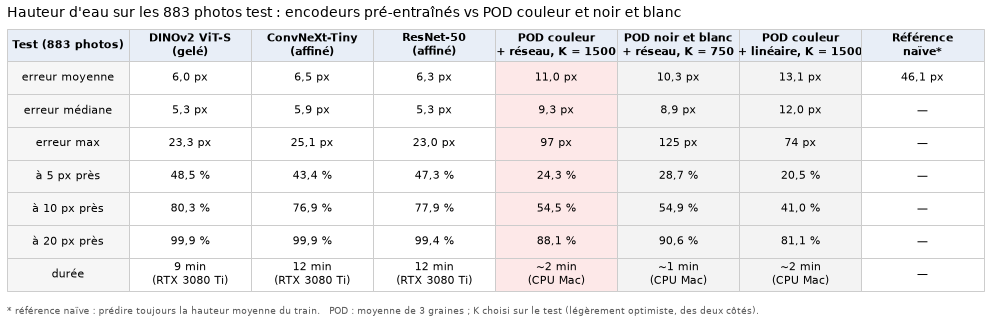

In [12]:
def metriques(p):
    e = np.abs(p - yte)
    return [f"{e.mean():.1f} px", f"{np.median(e):.1f} px", f"{e.max():.0f} px",
            f"{100 * (e <= 5).mean():.1f} %", f"{100 * (e <= 10).mean():.1f} %", f"{100 * (e <= 20).mean():.1f} %"]

colonnes = ["Test (883 photos)", "DINOv2 ViT-S\n(gelé)", "ConvNeXt-Tiny\n(affiné)", "ResNet-50\n(affiné)",
            f"POD couleur\n+ réseau, K = {K_best}", f"POD noir et blanc\n+ réseau, K = {K_gris}", f"POD couleur\n+ linéaire, K = {K_best}", "Référence\nnaïve*"]
encodeurs = {"DINOv2": ["6,0 px", "5,3 px", "23,3 px", "48,5 %", "80,3 %", "99,9 %"],
             "ConvNeXt": ["6,5 px", "5,9 px", "25,1 px", "43,4 %", "76,9 %", "99,9 %"],
             "ResNet": ["6,3 px", "5,3 px", "23,0 px", "47,3 %", "77,9 %", "99,4 %"]}
lignes_nom = ["erreur moyenne", "erreur médiane", "erreur max", "à 5 px près", "à 10 px près", "à 20 px près"]
pod_c, pod_g, lin_c = metriques(pred), metriques(pred_g), metriques(predictions_lin[K_best])
naif = [f"{np.abs(yte - ytr.mean()).mean():.1f} px"] + ["—"] * 5
lignes = [[n, encodeurs["DINOv2"][i], encodeurs["ConvNeXt"][i], encodeurs["ResNet"][i],
           pod_c[i].replace(".", ","), pod_g[i].replace(".", ","), lin_c[i].replace(".", ","), naif[i].replace(".", ",")]
          for i, n in enumerate(lignes_nom)]
lignes.append(["durée", "9 min\n(RTX 3080 Ti)", "12 min\n(RTX 3080 Ti)", "12 min\n(RTX 3080 Ti)", "~2 min\n(CPU Mac)", "~1 min\n(CPU Mac)", "~2 min\n(CPU Mac)", "—"])

fig, ax = plt.subplots(figsize=(18, 5.4)); ax.axis("off")
t = ax.table(cellText=lignes, colLabels=colonnes, cellLoc="center", colLoc="center", bbox=[0, 0.08, 1, 0.9])
t.auto_set_font_size(False); t.set_fontsize(11)
for (r, c), cell in t.get_celld().items():
    cell.set_edgecolor("#cccccc")
    if c == 4 and r > 0: cell.set_facecolor("#fde8e8")
    if c in (5, 6) and r > 0: cell.set_facecolor("#f3f3f3")
    if r == 0: cell.set_text_props(weight="bold"); cell.set_facecolor("#e8eef7")
    elif c == 0: cell.set_facecolor("#f6f6f6")
ax.set_title("Hauteur d'eau sur les 883 photos test : encodeurs pré-entraînés vs POD couleur et noir et blanc", fontsize=14, loc="left")
ax.text(0, 0.0, "* référence naïve : prédire toujours la hauteur moyenne du train.   POD : moyenne de 3 graines ; K choisi sur le test (légèrement optimiste, des deux côtés).",
        fontsize=9, color="#555", transform=ax.transAxes)
fig.savefig(FIG / "comparaison_encodeurs_pod.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Ce que fait l'erreur à l'image

### Exemples à ~5, ~10 et ~20 px (couleur)

Photos test à ±1 px de chaque erreur, au hasard, une par jour. Vert = annoté, rouge = prédit (POD couleur). Enregistrées dans `figures/couleur/erreurs_pod_XXpx.jpg`.

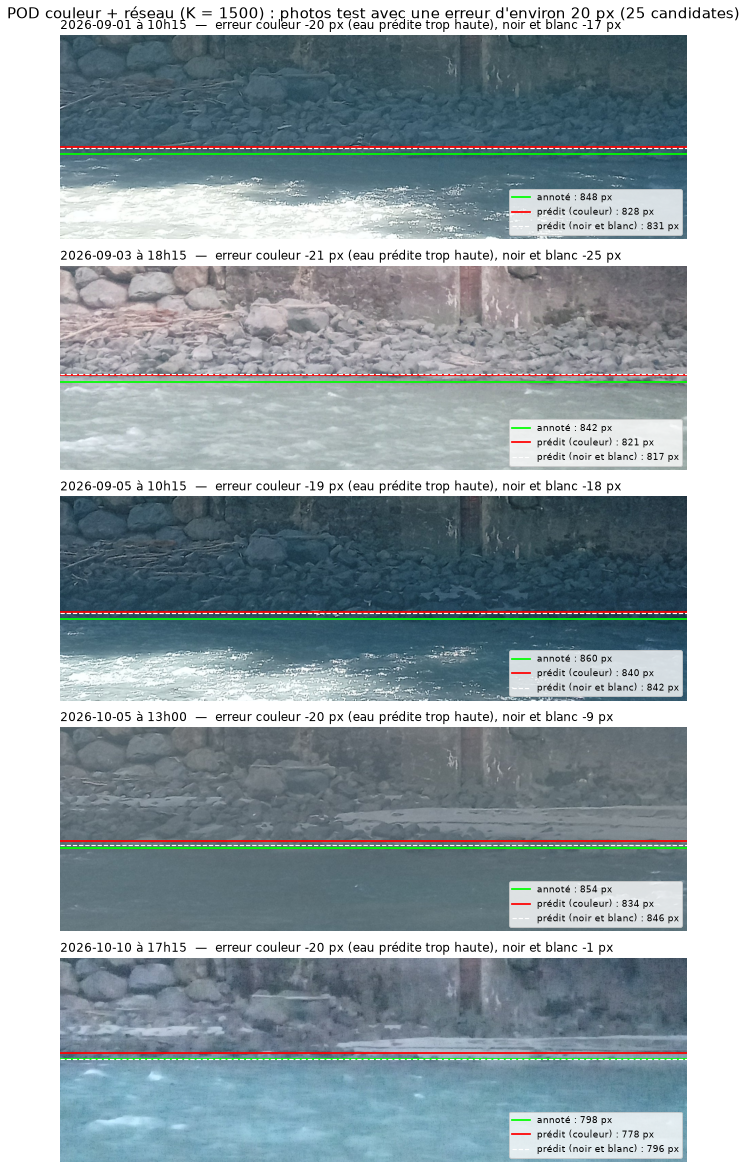

In [13]:
jours = pd.Series(noms_te).str[:10].to_numpy()
rng = np.random.default_rng(0)


def tracer_lignes(choix, chemin, titre, avec_normalisee=False):
    ncol = 2 if avec_normalisee else 1
    fig, axes = plt.subplots(len(choix), ncol, figsize=(16 * ncol / (1.4 if ncol == 2 else 1), 3.4 * len(choix)), squeeze=False)
    for ligne, i in zip(axes, choix):
        nom = noms_te[i]
        bande = decouper(Image.open(IMAGES / nom), cat.at[nom, "decalage_x"], cat.at[nom, "decalage_y"])
        vues = [bande] + ([np.clip(normaliser_couleur(bande) / 6 + 0.5, 0, 1)] if avec_normalisee else [])
        for ax, im in zip(ligne, vues):
            ax.imshow(im)
            ax.axhline(yte[i] - Y0, color="lime", lw=1.8, label=f"annoté : {yte[i]:.0f} px")
            ax.axhline(pred[i] - Y0, color="red", lw=1.8, label=f"prédit (couleur) : {pred[i]:.0f} px")
            ax.axhline(pred_g[i] - Y0, color="white", lw=1.2, ls="--", label=f"prédit (noir et blanc) : {pred_g[i]:.0f} px")
            ax.axis("off")
        sens = "eau prédite trop basse" if err[i] > 0 else "eau prédite trop haute"
        ligne[0].set_title(f"{nom[:10]} à {nom[11:13]}h{nom[13:15]}  —  erreur couleur {err[i]:+.0f} px ({sens}), noir et blanc {err_g[i]:+.0f} px",
                           loc="left", fontsize=12)
        ligne[0].legend(loc="lower right", fontsize=9)
        if avec_normalisee:
            ligne[1].set_title("ce que voit la POD : couleur, chaque canal centré réduit", loc="left", fontsize=11)
    fig.suptitle(titre, fontsize=15)
    plt.tight_layout()
    fig.savefig(chemin, dpi=80, pil_kwargs={"quality": 88})
    return fig


for cible in (5, 10, 20):
    cand = np.where(np.abs(np.abs(err) - cible) <= 1)[0]; rng.shuffle(cand)
    choix, vus = [], set()
    for i in cand:
        if jours[i] not in vus:
            choix.append(i); vus.add(jours[i])
        if len(choix) == 5:
            break
    choix.sort(key=lambda i: noms_te[i])
    fig = tracer_lignes(choix, FIG / f"erreurs_pod_{cible:02d}px.jpg",
                        f"POD couleur + réseau (K = {K_best}) : photos test avec une erreur d'environ {cible} px ({len(cand)} candidates)")
    if cible != 20:
        plt.close(fig)
plt.show()

### Les pires erreurs par tranche de hauteur d'eau

Les 6 pires erreurs de chaque tranche (au plus 2 par jour). À gauche la bande en couleur, à droite ce que voit la POD couleur. Pointillés blancs : prédiction du noir et blanc, pour comparer. Enregistrées dans `figures/couleur/pires_erreurs_*.jpg`.

In [14]:
TRANCHES = [(0, 760, "eau_haute", "eau haute (< 760 px)"), (760, 830, "760-830", "760 - 830 px"),
            (830, 850, "830-850", "830 - 850 px"), (850, 2000, "eau_basse", "eau basse (> 850 px)")]
lignes_tr = []
for lo, hi, court, nom_t in TRANCHES:
    idx = np.where((yte >= lo) & (yte < hi))[0]
    lignes_tr.append({"tranche": nom_t, "photos": len(idx), "couleur : erreur moyenne (px)": np.abs(err[idx]).mean(),
                      "noir et blanc : erreur moyenne (px)": np.abs(err_g[idx]).mean(),
                      "couleur : erreur max (px)": np.abs(err[idx]).max(), "noir et blanc : erreur max (px)": np.abs(err_g[idx]).max()})
    idx = idx[np.argsort(-np.abs(err[idx]))]
    choix, compte = [], {}
    for i in idx:
        if compte.get(jours[i], 0) < 2:
            choix.append(i); compte[jours[i]] = compte.get(jours[i], 0) + 1
        if len(choix) == 6:
            break
    fig = tracer_lignes(choix, FIG / f"pires_erreurs_{court}.jpg",
                        f"POD couleur + réseau (K = {K_best}) : les 6 pires erreurs, {nom_t}", avec_normalisee=True)
    plt.close(fig)
pd.DataFrame(lignes_tr).set_index("tranche").round(1)

,photos,couleur : erreur moyenne (px),noir et blanc : erreur moyenne (px),couleur : erreur max (px),noir et blanc : erreur max (px)
tranche,,,,,
eau haute (< 760 px),133,10.9,11.1,96.8,125.1
760 - 830 px,150,7.3,6.1,20.1,21.2
830 - 850 px,160,8.3,6.8,31.3,27.4
eau basse (> 850 px),440,13.2,12.7,46.4,43.7


### Erreur de reconstruction de l'image vs erreur du réseau

Erreur de reconstruction avec K_best modes : $\|x - x_K\| / \|x - \bar{x}\|$, calculée sans reconstruire l'image grâce à l'orthonormalité des modes : $\|x - x_K\|^2 = \|x - \bar{x}\|^2 - \sum_{k \le K} a_k^2$. Une figure pour toutes les photos test, une par tranche de hauteur.

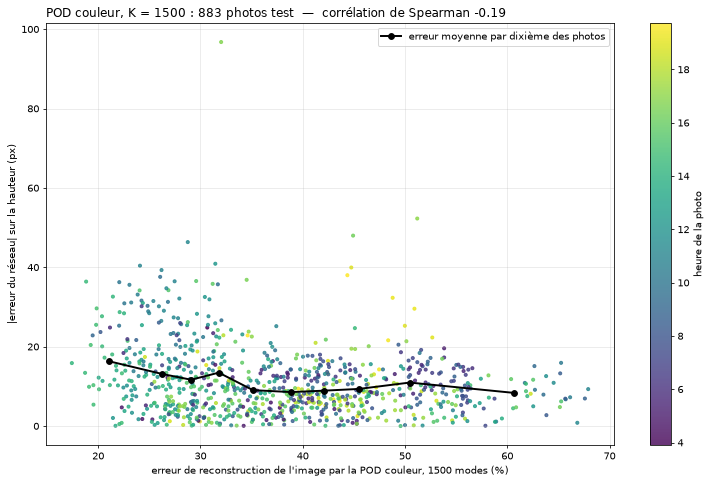

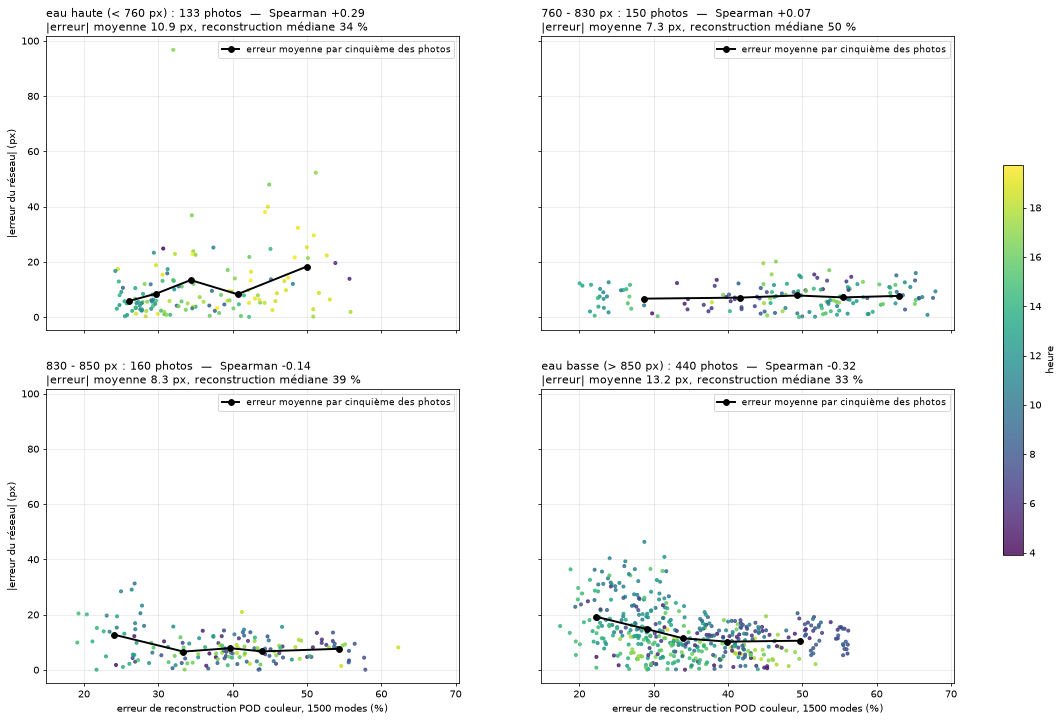

In [15]:
g = np.isfinite(hauteur.reindex(fichiers["test"]).to_numpy())
n2 = np.sum((X["test"][g].astype(np.float64) - xbar) ** 2, axis=1)
rec = 100 * np.sqrt(np.clip(n2 - np.sum(jeux["test"][0][:, :K_best] ** 2, axis=1), 0, None) / n2)
r = lambda a, b: pd.Series(a).corr(pd.Series(b), method="spearman")

fig, a = plt.subplots(figsize=(11, 7))
sc = a.scatter(rec, np.abs(err), s=10, c=heures_te, cmap="viridis", alpha=.8)
bins = np.quantile(rec, np.linspace(0, 1, 11)); mil = (bins[1:] + bins[:-1]) / 2
a.plot(mil, [np.abs(err)[(rec >= lo) & (rec <= hi)].mean() for lo, hi in zip(bins[:-1], bins[1:])], "k-o", lw=2,
       label="erreur moyenne par dixième des photos")
a.set_xlabel(f"erreur de reconstruction de l'image par la POD couleur, {K_best} modes (%)")
a.set_ylabel("|erreur du réseau| sur la hauteur (px)"); a.grid(alpha=.3); a.legend()
a.set_title(f"POD couleur, K = {K_best} : {len(yte)} photos test  —  corrélation de Spearman {r(rec, np.abs(err)):+.2f}", loc="left")
plt.colorbar(sc, ax=a, label="heure de la photo")
plt.tight_layout(); fig.savefig(FIG / "correlation_reconstruction_erreur.png", dpi=110)

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharex=True, sharey=True)
for a, (lo, hi, _, nom_t) in zip(axes.ravel(), TRANCHES):
    m = (yte >= lo) & (yte < hi); x, y = rec[m], np.abs(err[m])
    sc = a.scatter(x, y, s=10, c=heures_te[m], cmap="viridis", alpha=.8, vmin=heures_te.min(), vmax=heures_te.max())
    q5 = np.quantile(x, np.linspace(0, 1, 6)); mil = (q5[1:] + q5[:-1]) / 2
    a.plot(mil, [y[(x >= a0) & (x <= a1)].mean() for a0, a1 in zip(q5[:-1], q5[1:])], "k-o", lw=2, label="erreur moyenne par cinquième des photos")
    a.set_title(f"{nom_t} : {m.sum()} photos  —  Spearman {r(x, y):+.2f}\n|erreur| moyenne {y.mean():.1f} px, reconstruction médiane {np.median(x):.0f} %",
                loc="left", fontsize=11)
    a.grid(alpha=.3); a.legend(fontsize=9)
for a in axes[1]: a.set_xlabel(f"erreur de reconstruction POD couleur, {K_best} modes (%)")
for a in axes[:, 0]: a.set_ylabel("|erreur du réseau| (px)")
fig.colorbar(sc, ax=axes, label="heure", fraction=0.02)
fig.savefig(FIG / "correlation_reconstruction_erreur_par_hauteur.png", dpi=110, bbox_inches="tight")
plt.show()

### Reconstructions de 100 photos test très différentes

100 photos **test** (jamais vues par la POD), choisies les plus différentes possible (tirage du point le plus éloigné sur les 50 premiers coefficients), reconstruites avec 1, 2, 4, ..., 2048 puis tous les modes. Un fichier par photo dans `figures/couleur/pod_reconstructions/`.

100 fichiers ; erreur de reconstruction avec tous les modes : médiane 36 %


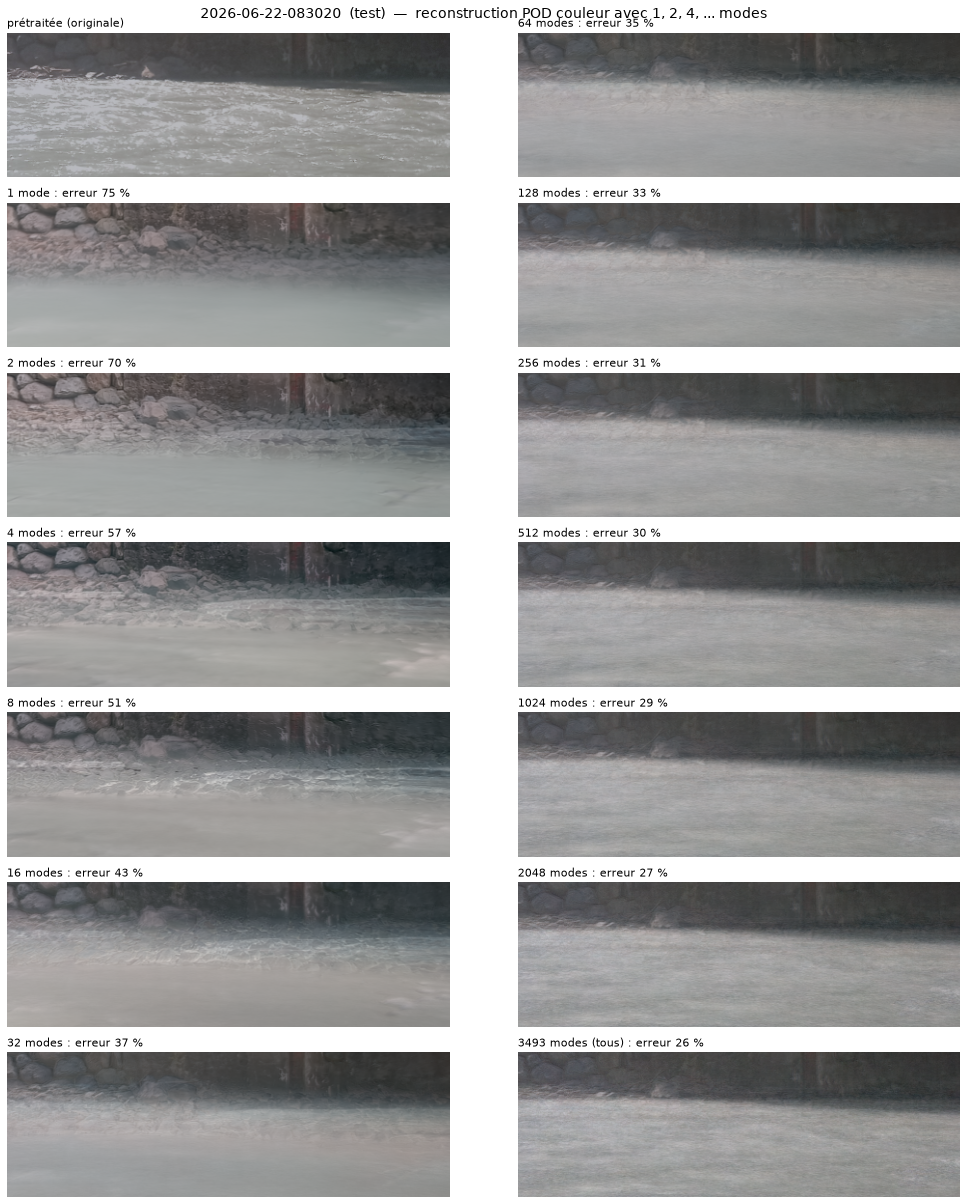

In [16]:
Ct = coefs["test"][:, :50] / coefs["test"][:, :50].std(axis=0)
choix = [int(np.argmax(np.linalg.norm(Ct - Ct.mean(axis=0), axis=1)))]
dist = np.linalg.norm(Ct - Ct[choix[0]], axis=1)
while len(choix) < 100:
    i = int(np.argmax(dist)); choix.append(i); dist = np.minimum(dist, np.linalg.norm(Ct - Ct[i], axis=1))
choix.sort(key=lambda i: fichiers["test"][i])

KS_REC = [2 ** i for i in range(12)] + [K_MAX]
dossier = FIG / "pod_reconstructions"; dossier.mkdir(exist_ok=True)
for f in dossier.glob("*"):
    f.unlink()
erreurs_rec = []
for n, i in enumerate(choix, 1):
    x, a = X["test"][i], coefs["test"][i]
    nx = np.linalg.norm(x - xbar)
    panneaux = [("prétraitée (originale)", x)]
    for k in KS_REC:
        rk = reconstruire(a, k)
        e = np.linalg.norm(x - rk) / nx
        panneaux.append((f"{k} mode{'s' if k > 1 else ''}{' (tous)' if k == K_MAX else ''} : erreur {100 * e:.0f} %", rk))
    erreurs_rec.append(e)
    fig, axes = plt.subplots(7, 2, figsize=(15, 17.5))
    for ax, (t, im) in zip(axes.T.ravel(), panneaux):
        ax.imshow(afficher(im)); ax.set_title(t, loc="left", fontsize=11); ax.axis("off")
    nom = fichiers["test"][i]
    fig.suptitle(f"{nom[:-4]}  (test)  —  reconstruction POD couleur avec 1, 2, 4, ... modes", fontsize=14)
    plt.tight_layout(); fig.savefig(dossier / f"{n:03d}_{nom[:-4]}_test.jpg", dpi=80, pil_kwargs={"quality": 88})
    if n > 1:
        plt.close(fig)
print(f"{len(choix)} fichiers ; erreur de reconstruction avec tous les modes : médiane {100 * np.median(erreurs_rec):.0f} %")
plt.show()